# WorldPop Population Data API Workflow

## Objective

Collect a WorldPop population raster for disaster impact assessment and save a cleaned NumPy array for downstream preprocessing.

## Outputs

- `datasets/population_data.tif`
- `datasets/population_clean.npy`
- `datasets/population_metadata.json`
- `datasets/population_selected_metadata.json`


In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import rasterio


BASE_URL = "https://hub.worldpop.org/rest/data/pop/wpgp"
COUNTRY_ISO3 = "IND"
PREFERRED_YEAR = 2020
REQUEST_TIMEOUT = 60

current_dir = Path.cwd()
PROJECT_ROOT = current_dir.parent if current_dir.name == "notebooks" else current_dir
DATA_DIR = PROJECT_ROOT / "datasets"
DATA_DIR.mkdir(parents=True, exist_ok=True)

METADATA_PATH = DATA_DIR / "population_metadata.json"
SELECTED_METADATA_PATH = DATA_DIR / "population_selected_metadata.json"
RASTER_PATH = DATA_DIR / "population_data.tif"
CLEAN_ARRAY_PATH = DATA_DIR / "population_clean.npy"

print(f"Project root: {PROJECT_ROOT}")
print(f"WorldPop catalogue: {BASE_URL}")


Project root: C:\Users\aashi\PycharmProjects\AI-Based Disaster Response Management System for Resource Allocation and Relief Coordination
WorldPop catalogue: https://hub.worldpop.org/rest/data/pop/wpgp


## 1. Load WorldPop Catalogue

The notebook first tries the WorldPop API. If the network is unavailable, it uses the existing local metadata file so the workflow remains reproducible offline.


In [2]:
def fetch_worldpop_metadata(base_url=BASE_URL, cache_path=METADATA_PATH):
    try:
        response = requests.get(base_url, timeout=REQUEST_TIMEOUT)
        response.raise_for_status()
        metadata = response.json()

        with cache_path.open("w", encoding="utf-8") as file:
            json.dump(metadata, file, indent=4)

        print(f"Fetched metadata from API and cached it at {cache_path}")
        return metadata

    except requests.RequestException as error:
        if cache_path.exists():
            print(f"API request failed: {error}")
            print(f"Using cached metadata from {cache_path}")
            with cache_path.open("r", encoding="utf-8") as file:
                return json.load(file)

        raise RuntimeError(
            "WorldPop metadata could not be downloaded and no cached metadata file exists."
        ) from error


metadata = fetch_worldpop_metadata()
records = metadata.get("data", metadata if isinstance(metadata, list) else [])

if not records:
    raise ValueError("WorldPop metadata did not contain any dataset records.")

metadata_df = pd.DataFrame(records)
metadata_df["popyear"] = pd.to_numeric(metadata_df["popyear"], errors="coerce").astype("Int64")
metadata_df["iso3"] = metadata_df["iso3"].str.upper()

metadata_df.head()


Fetched metadata from API and cached it at C:\Users\aashi\PycharmProjects\AI-Based Disaster Response Management System for Resource Allocation and Relief Coordination\datasets\population_metadata.json


,id,title,popyear,iso3
0,1325,The spatial distribution of population in 2000...,2000,AUS
1,1326,The spatial distribution of population in 2000...,2000,RUS
2,1327,The spatial distribution of population in 2000...,2000,BRA
3,1328,The spatial distribution of population in 2000...,2000,CAN
4,1329,The spatial distribution of population in 2000...,2000,CZE


In [3]:
print("Metadata rows:", len(metadata_df))
print("Available columns:", metadata_df.columns.tolist())
print("Year range:", int(metadata_df["popyear"].min()), "to", int(metadata_df["popyear"].max()))
print("Countries:", metadata_df["iso3"].nunique())


Metadata rows: 5221
Available columns: ['id', 'title', 'popyear', 'iso3']
Year range: 2000 to 2020
Countries: 249


## 2. Select Country and Year

The project uses India by default. The notebook chooses the preferred year when available; otherwise it falls back to the latest available year for that country.


In [4]:
country_records = (
    metadata_df[metadata_df["iso3"] == COUNTRY_ISO3]
    .dropna(subset=["popyear"])
    .sort_values("popyear")
)

if country_records.empty:
    raise ValueError(f"No WorldPop records found for ISO3 code {COUNTRY_ISO3!r}.")

available_years = country_records["popyear"].astype(int).tolist()
selected_year = PREFERRED_YEAR if PREFERRED_YEAR in available_years else max(available_years)

selected_record = (
    country_records[country_records["popyear"] == selected_year]
    .iloc[-1]
    .to_dict()
)

with SELECTED_METADATA_PATH.open("w", encoding="utf-8") as file:
    json.dump(selected_record, file, indent=4)

print(f"Selected country: {COUNTRY_ISO3}")
print(f"Selected year: {selected_year}")
print(f"Selected record id: {selected_record.get('id')}")
print(selected_record.get("title"))


Selected country: IND
Selected year: 2020
Selected record id: 6527
The spatial distribution of population in 2020, India


## 3. Resolve and Download Raster

The WorldPop catalogue gives country/year records, while the GeoTIFF files are served from the WorldPop data host. The resolver checks stable URL patterns and only downloads a file after confirming that a candidate exists.


In [5]:
def candidate_raster_urls(iso3, year):
    iso3 = iso3.upper()
    lower_iso3 = iso3.lower()
    return [
        f"https://data.worldpop.org/GIS/Population/Global_2000_2020/{year}/{iso3}/{lower_iso3}_ppp_{year}.tif",
        f"https://data.worldpop.org/GIS/Population/Global_2000_2020/{year}/{iso3}/{lower_iso3}_ppp_{year}_UNadj.tif",
        f"https://data.worldpop.org/GIS/Population/Global_2000_2020/{year}/{iso3}/{lower_iso3}_ppp_{year}_constrained.tif",
    ]


def url_exists(url):
    try:
        response = requests.head(url, allow_redirects=True, timeout=REQUEST_TIMEOUT)
        return response.status_code == 200
    except requests.RequestException:
        return False


def resolve_raster_url(iso3, year):
    for url in candidate_raster_urls(iso3, year):
        if url_exists(url):
            return url

    raise FileNotFoundError(
        f"No downloadable WorldPop raster URL was found for {iso3} {year}."
    )


raster_url = resolve_raster_url(COUNTRY_ISO3, selected_year)
print(raster_url)


https://data.worldpop.org/GIS/Population/Global_2000_2020/2020/IND/ind_ppp_2020.tif


In [6]:
def download_file(url, output_path, chunk_size=1024 * 1024):
    response = requests.get(url, stream=True, timeout=REQUEST_TIMEOUT)
    response.raise_for_status()

    total_bytes = int(response.headers.get("content-length", 0))
    downloaded_bytes = 0
    started_at = time.time()

    with output_path.open("wb") as file:
        for chunk in response.iter_content(chunk_size=chunk_size):
            if chunk:
                file.write(chunk)
                downloaded_bytes += len(chunk)

    elapsed = max(time.time() - started_at, 0.001)
    size_mb = downloaded_bytes / (1024 * 1024)
    expected_mb = total_bytes / (1024 * 1024) if total_bytes else None

    if expected_mb:
        print(f"Downloaded {size_mb:.1f} MB of {expected_mb:.1f} MB in {elapsed:.1f}s")
    else:
        print(f"Downloaded {size_mb:.1f} MB in {elapsed:.1f}s")


if RASTER_PATH.exists() and RASTER_PATH.stat().st_size > 0:
    print(f"Raster already exists: {RASTER_PATH}")
else:
    download_file(raster_url, RASTER_PATH)

print(f"Raster path: {RASTER_PATH}")
print(f"Raster size: {RASTER_PATH.stat().st_size / (1024 * 1024):.1f} MB")


Raster already exists: C:\Users\aashi\PycharmProjects\AI-Based Disaster Response Management System for Resource Allocation and Relief Coordination\datasets\population_data.tif
Raster path: C:\Users\aashi\PycharmProjects\AI-Based Disaster Response Management System for Resource Allocation and Relief Coordination\datasets\population_data.tif
Raster size: 747.7 MB


## 4. Inspect Raster


In [7]:
with rasterio.open(RASTER_PATH) as dataset:
    raster_profile = dataset.profile
    raster_bounds = dataset.bounds
    raster_crs = dataset.crs
    raster_nodata = dataset.nodata
    raster_shape = (dataset.height, dataset.width)

print("Width:", raster_shape[1])
print("Height:", raster_shape[0])
print("Bands:", raster_profile["count"])
print("CRS:", raster_crs)
print("Bounds:", raster_bounds)
print("NoData value:", raster_nodata)


Width: 35040
Height: 34507
Bands: 1
CRS: EPSG:4326
Bounds: BoundingBox(left=68.19583234055, bottom=6.755833642309984, right=97.39583222375, top=35.51166686061998)
NoData value: -99999.0


## 5. Clean Population Values

WorldPop pixel values represent estimated population count per grid cell. The notebook computes clean statistics block-by-block and saves a compact preview array. The original GeoTIFF remains the authoritative population source for coordinate lookups.


In [8]:
def clean_population_block(block, nodata_value):
    block = block.astype("float32", copy=False)

    if nodata_value is not None:
        block = np.where(block == nodata_value, np.nan, block)

    block = np.where(block < 0, np.nan, block)
    return block.astype("float32", copy=False)


def build_population_stats(raster_path=RASTER_PATH):
    with rasterio.open(raster_path) as dataset:
        valid_count = 0
        total_sum = 0.0
        min_value = np.inf
        max_value = -np.inf

        for _, window in dataset.block_windows(1):
            block = dataset.read(1, window=window)
            block_clean = clean_population_block(block, dataset.nodata)

            valid = np.isfinite(block_clean)
            if valid.any():
                values = block_clean[valid]
                valid_count += int(values.size)
                total_sum += float(values.sum(dtype="float64"))
                min_value = min(min_value, float(values.min()))
                max_value = max(max_value, float(values.max()))

        mean_value = total_sum / valid_count if valid_count else np.nan
        return {
            "shape": (dataset.height, dataset.width),
            "valid_cells": valid_count,
            "minimum": min_value if valid_count else np.nan,
            "maximum": max_value if valid_count else np.nan,
            "mean": mean_value,
            "total_population_estimate": total_sum,
        }


population_stats = build_population_stats()

print("Shape:", population_stats["shape"])
print("Valid cells:", population_stats["valid_cells"])
print("Minimum:", population_stats["minimum"])
print("Maximum:", population_stats["maximum"])
print("Mean:", population_stats["mean"])
print("Total population estimate:", population_stats["total_population_estimate"])


Shape: (34507, 35040)
Valid cells: 140103033
Minimum: 0.0
Maximum: 1918.795166015625
Mean: 10.494388858652398
Total population estimate: 1470295708.5786092


## 6. Preview Raster

The plot uses a downsampled view so large rasters remain responsive inside Jupyter.


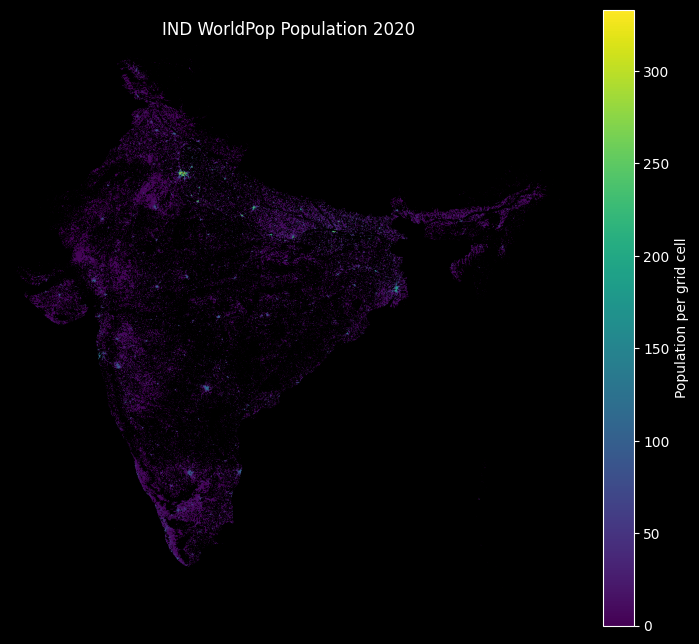

In [9]:
with rasterio.open(RASTER_PATH) as dataset:
    preview_height = min(1000, dataset.height)
    preview_width = max(1, int(dataset.width * preview_height / dataset.height))
    preview = dataset.read(
        1,
        out_shape=(preview_height, preview_width),
        masked=True,
    ).astype("float32")

    population_preview = preview.filled(np.nan)
    population_preview = np.where(population_preview < 0, np.nan, population_preview)

plt.figure(figsize=(9, 8))
plt.imshow(population_preview, cmap="viridis")
plt.colorbar(label="Population per grid cell")
plt.title(f"{COUNTRY_ISO3} WorldPop Population {selected_year}")
plt.axis("off")
plt.show()


## 7. Save Compact Clean Preview Array


In [10]:
np.save(CLEAN_ARRAY_PATH, population_preview.astype("float32"))

print(f"Compact clean preview array saved: {CLEAN_ARRAY_PATH}")
print(f"Preview shape: {population_preview.shape}")
print("The full-resolution population source remains population_data.tif.")


Compact clean preview array saved: C:\Users\aashi\PycharmProjects\AI-Based Disaster Response Management System for Resource Allocation and Relief Coordination\datasets\population_clean.npy
Preview shape: (1000, 1015)
The full-resolution population source remains population_data.tif.


## 8. Validate Coordinate Lookup

This helper is the same style of lookup used later in preprocessing. It checks bounds and NoData values instead of swallowing every error.


In [11]:
def get_population_at(latitude, longitude, raster_path=RASTER_PATH):
    with rasterio.open(raster_path) as dataset:
        if not (
            dataset.bounds.left <= longitude <= dataset.bounds.right
            and dataset.bounds.bottom <= latitude <= dataset.bounds.top
        ):
            return 0.0

        row, col = dataset.index(longitude, latitude)
        value = float(dataset.read(1, window=((row, row + 1), (col, col + 1)))[0, 0])

        if dataset.nodata is not None and value == dataset.nodata:
            return 0.0
        if value < 0 or np.isnan(value):
            return 0.0

        return value


sample_population = get_population_at(28.6139, 77.2090)
print(f"Population grid-cell estimate near New Delhi: {sample_population:.2f}")


Population grid-cell estimate near New Delhi: 45.35


In [12]:
print("=" * 48)
print("WorldPop workflow completed successfully")
print(f"Country/year: {COUNTRY_ISO3} {selected_year}")
print(f"Raster: {RASTER_PATH}")
print(f"Clean array: {CLEAN_ARRAY_PATH}")
print("Ready for Data_Preprocessing.ipynb")
print("=" * 48)


WorldPop workflow completed successfully
Country/year: IND 2020
Raster: C:\Users\aashi\PycharmProjects\AI-Based Disaster Response Management System for Resource Allocation and Relief Coordination\datasets\population_data.tif
Clean array: C:\Users\aashi\PycharmProjects\AI-Based Disaster Response Management System for Resource Allocation and Relief Coordination\datasets\population_clean.npy
Ready for Data_Preprocessing.ipynb
